# Modelling Popularity Dynamics of Post-200 Movies

Inspired by the work of Richier et al. on Youtube viewcounts, we adapt 
the methods used and apply them to the user review dataset [cite]. f treating popularity as a static metric, we investigate the evolution of views through cumulative time series. This enables us to analyze the underlying popularity mechanisms and categorize movies in too viral vs non-viral growth. 

We start out with an in-depth analysis of the dynamics of the top 500 most reviewed movies released post-2000, and then expand our investigation to the top 10,000 movies from post 2000 era.
The year 2000 was choosen arbitrarily as a cutoff to mitigate outliers and anomalys. Because the review plattform was established around 1996, the reviews published can not accuratly model the popularity of movies released prior to this. The choosen cutoff ensures that all movies that are part of our investigation are accurately captured in their populairty across their full lifetime.

In the following we will use the folowing metrics used by Richier et. al [cite]

|Modell Name|Population|Growth|Function|
|---|---|---|---|
|Logistic model|Fixed target population|Viral|$S(t) = \frac{M}{1 + \left(\frac{M - S(0)}{S(0)}\right) e^{-\lambda t}}$|
|Gompertz model|Fixed target population|Viral|$S(t) = M \exp\left(-\log\left(\frac{M}{S(0)}\right) \exp(-\lambda t)\right)$|
|Negative exponential model|Fixed target population|Non-viral|$S(t) = S(0) + (M - S(0))(1 - e^{-\lambda t})$|
|Linear model|Growing target population|Non-viral|$S(t) = S(0) + kt$|
|Modified negative exponential model|Growing target population|Non-viral|$S(t) = S(0) + (M - S(0))(1 - e^{-\lambda t}) + kt$|
|Modified Gompertz model|Growing target population|Viral|$S(t) = M \exp\left(-\log\left(\frac{M}{S(0)}\right) \exp(-\lambda t)\right) + kt$|

## Preliminary analysis Top 500
To establish a baseline we start of with an indepth analysis of the top 500 most rated movies post 2000.

We then look at how well our models fit the data. How the modell are distributed in our data, how well these modells predict future growth if trained on only 50% of the data. how the growth models are distibuted amongst movie popularity calsses and lastly how they are distributed in the top 10% best rated movies.

In [7]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


TOP_N = 500

In [2]:
movies_dtype = {
    "movieId": "int32",
    "title": "string",
    "genres": "string"
}
ratings_dtype = {
    "userId": "int32",
    "movieId": "int32",
    "rating": "float32",
    "timestamp": "int64"
}
movies_df = pd.read_csv("./../data/ml-latest/movies.csv", dtype=movies_dtype)               # Load df with explicit datatypes
ratings_df = pd.read_csv("./../data/ml-latest/ratings.csv", dtype=ratings_dtype)            #

movies_df["year"] = movies_df["title"].str.extract(r"\((\d{4})\)").astype("Int64")          # Add coll for release year based on () in name
recent_movies = movies_df[movies_df["year"] >= 2000].copy()


recent_movie_ids = recent_movies["movieId"]                                                 # Filter the movies so only >2000 and in top 500 most reviews remain
review_counts = ratings_df["movieId"].value_counts()
review_counts.head()
recent_movie_review_counts = review_counts[review_counts.index.isin(recent_movie_ids)]

top_movie_ids = recent_movie_review_counts.nlargest(TOP_N).index.values

# Filter the movies
movies_df = recent_movies[recent_movies["movieId"].isin(top_movie_ids)]
ratings_df = ratings_df[ratings_df["movieId"].isin(top_movie_ids)]

In [3]:
movie_time_series = {}

for movie_id in movies_df["movieId"]:                                                           # Convert all reviews into a normalized timeseries
    movie_ratings = ratings_df[ratings_df["movieId"] == movie_id].sort_values("timestamp")
    timestamps = movie_ratings["timestamp"].values


    elapsed_time = timestamps - timestamps[0]
    total_time = elapsed_time[-1]

    cumulative_counts = np.arange(1, len(movie_ratings) + 1, dtype=float)
    max_count = cumulative_counts[-1]

    t_norm = elapsed_time / total_time if total_time > 0 else elapsed_time
    y_norm = cumulative_counts / max_count

    movie_time_series[movie_id] = {
        "title": movies_df.loc[movies_df["movieId"] == movie_id, "title"].values[0],
        "t": t_norm,
        "y": y_norm,
        "total_reviews": max_count,
        "avg_rating": movie_ratings["rating"].mean()
    }

## 2. Defining and Fitting the Growth Models

With our time series normalized, we define the six bio-inspired growth models mathematically. Using the `curve_fit` optimization function from `scipy.optimize`, we fit each of these six models to the normalized time series of every movie. 

To determine the optimal model for each movie, the algorithm calculates two key metrics:
1. **Mean Error Rate (MER):** Measures the average proportional deviation of the predicted curve from the empirical data.
2. **Goodness of Fit (GOF) / Mean Squared Error (MSE):** Evaluates the variance of the residuals. The model with the lowest GOF score is selected a specific movie.

In [14]:
# Viral, Fixed Target Population                                        # Define all our models
def logistic(t, lam, S0):
    M = 1.0
    return M/(1+((M-S0)/S0)*np.exp(-lam*M*t))

def gompertz(t, lam, S0):
    M = 1.0
    return M*np.exp(-np.log(M/S0)*np.exp(-lam*t))

# Non-viral, Fixed target population
def neg_exponential(t, lam, S0):
    M = 1.0
    return S0 + (M - S0) * (1.0 - np.exp(-lam * t))

# Non-viral, Growing target population
def linear(t, lam, S0):
    return S0 + lam * t

def mod_neg_exponential(t, lam, k, S0):
    M = 1.0
    return S0 + (M - S0) * (1.0 - np.exp(-lam*t)) + k * t

# Viral, Growing target population
def mod_gompertz(t, lam, k, S0):
    M = 1.0
    return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t

def one_par_wrapper(model_func, S0):                                    # Wrapper function so we can use Scipy.optimize.curvefit
    def wrapped_model(t, lam):
        return model_func(t, lam, S0)
    return wrapped_model

def two_par_wrapper(model_func, S0):
    def wrapped_model(t, lam, k):
        return model_func(t, lam, k, S0)
    return wrapped_model

models = {
    "Linear":linear,
    "Logistic": logistic,
    "Gompertz": gompertz,
    "Negative Exponential": neg_exponential,
    "Mod. Neg. Exponential": mod_neg_exponential,
    "Mod. Gompertz": mod_gompertz,
}

def get_best_fit(t_vals, y_vals, models, one_par_wrapper, two_par_wrapper):                 # i just factored out my function fitting to keep code atleast a little clean
    n = len(y_vals)
    if n == 0:
        return {"name": "Unclassified (No Data)", "mer": None, "gof": None, "msc": None, "lam": None, "k": None}

    S0 = y_vals[0] if y_vals[0] > 0 else 1e-5
    candidates = []

    for model_name, model_func in models.items():
        try:
            if model_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
                wrapped_func = two_par_wrapper(model_func, S0)
                p0 = [1.0, 0.1]     # initial guess for lam and k
                p = 2
                popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")
                opt_lam, opt_k = popt
                y_pred = wrapped_func(t_vals, opt_lam, opt_k)
                p = 2
            else:
                wrapped_func = one_par_wrapper(model_func, S0)

                popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=[1.0], method="lm")
                p0 = [1.0]          # initial guess for lam
                p = 1
                opt_lam = popt
                opt_k = None
                y_pred = wrapped_func(t_vals, opt_lam)
                p = 1

            mer = np.mean(np.abs(y_vals - y_pred) / (y_vals + 1.0))
            msc = np.sum((y_pred - y_vals) ** 2)
            df = n - p
            if df > 0:
                gof = (1.0/df) * msc
            else:
                gof = float("inf")
            
            candidates.append({"name": model_name, "mer": mer, "msc": msc, "gof": gof, "lam": opt_lam, "k": opt_k})
        except Exception:
            continue

    if not candidates:
        return {"name": "Unclassified (Fit Failed)", "mer": None, "gof": None, "msc": None, "lam": None, "k": None}

    return min(candidates, key=lambda x: x["gof"])

In [15]:
results = []

for movie_id, data in movie_time_series.items():
    best = get_best_fit(data["t"], data["y"], models, one_par_wrapper, two_par_wrapper)

    results.append({
        "movieId": movie_id,
        "title": data["title"],
        "total_reviews": data["total_reviews"],
        "avg_rating": data["avg_rating"],
        "best_model": best["name"],
        "MER": best["mer"],
        "GOF": best["gof"],
        "MSC": best["msc"],
        "opt_lam": best["lam"],
        "opt_k": best["k"]
    })

df_results = pd.DataFrame(results)
print(df_results["best_model"].value_counts())

/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")


best_model
Mod. Neg. Exponential    259
Mod. Gompertz            213
Gompertz                  25
Negative Exponential       1
Linear                     1
Logistic                   1
Name: count, dtype: int64


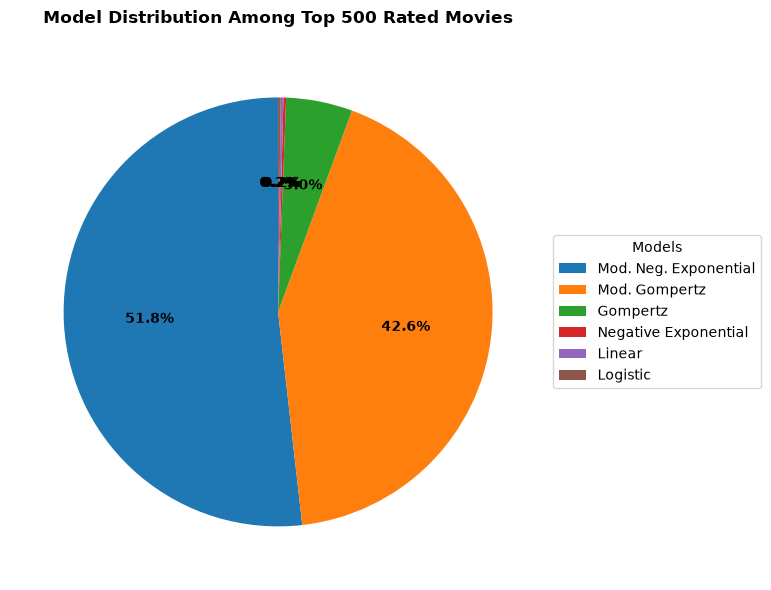

In [16]:
model_counts = df_results["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold", color="black")

ax.legend(
    wedges, 
    model_counts.index, 
    title="Models", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Model Distribution Among Top {TOP_N} Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()

## 3. Results of the Top 500 Analysis

The algorithmic classification successfully converges for all 500 evaluated movies. When comparing our findings to the results of Richier et al., we observe a difference in popularity dynamics. 

In our MovieLens analysis, the **Modified Negative Exponential** and **Modified Gompertz** models overwhelmingly dominate, containing 94.4% of the classified movies.
The results in the original paper, featured a rather more diverse set of featured models. Youtube videos have a rapid viral burst, while the movies appear to grow often in disctinct two phases
Unlike youtube videos, many movies experience an initial surge


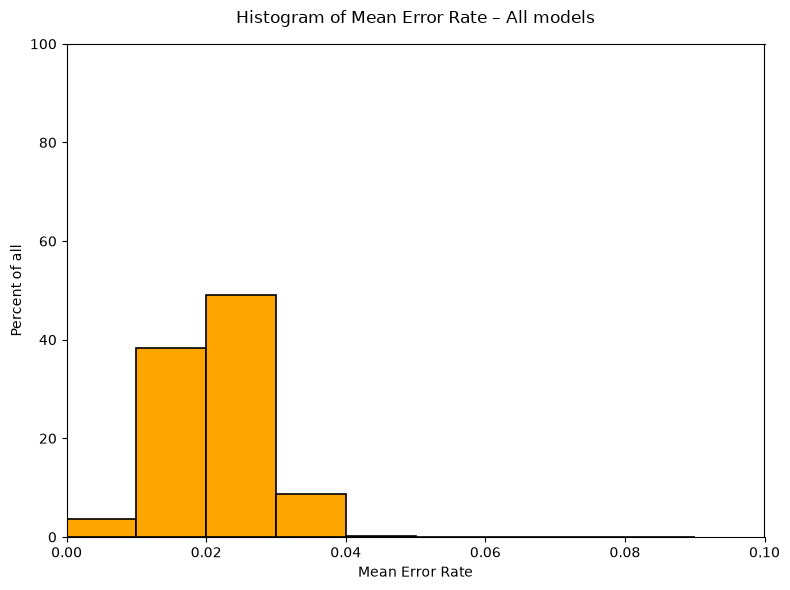

In [ ]:
mer_data = df_results["MER"].dropna().values

bins = np.arange(0.0, 0.1, 0.01)

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

weights = np.ones(len(mer_data)) / len(mer_data) * 100

ax.hist(
    mer_data,
    bins=bins,
    weights=weights,
    color="orange",
    edgecolor="black",
    linewidth=1.2,
)

ax.set_title("Histogram of Mean Error Rate – All models", fontsize=12, pad=15)
ax.set_xlabel("Mean Error Rate", fontsize=10)
ax.set_ylabel("Percent of all", fontsize=10)

ax.set_xlim(0.00, 0.1)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

## 4. Evaluating Model Fit Quality

Looking into the Mean Error Rate (MER) distribution, we see that almost all our movies are categorized with a MER lower than 0.05[cite: 1]. This indicates that our bio-inspired models fit the empirical data extremely well, successfully capturing the underlying popularity dynamics[cite: 1]. 

While MER confirms the overall validity of the fits, we utilize the Goodness of Fit (GOF) to make granular distinctions between competing models during the classification phase, as it calculates exactly how well our modeled functions capture the underlying data by heavily penalizing larger deviations[cite: 1].

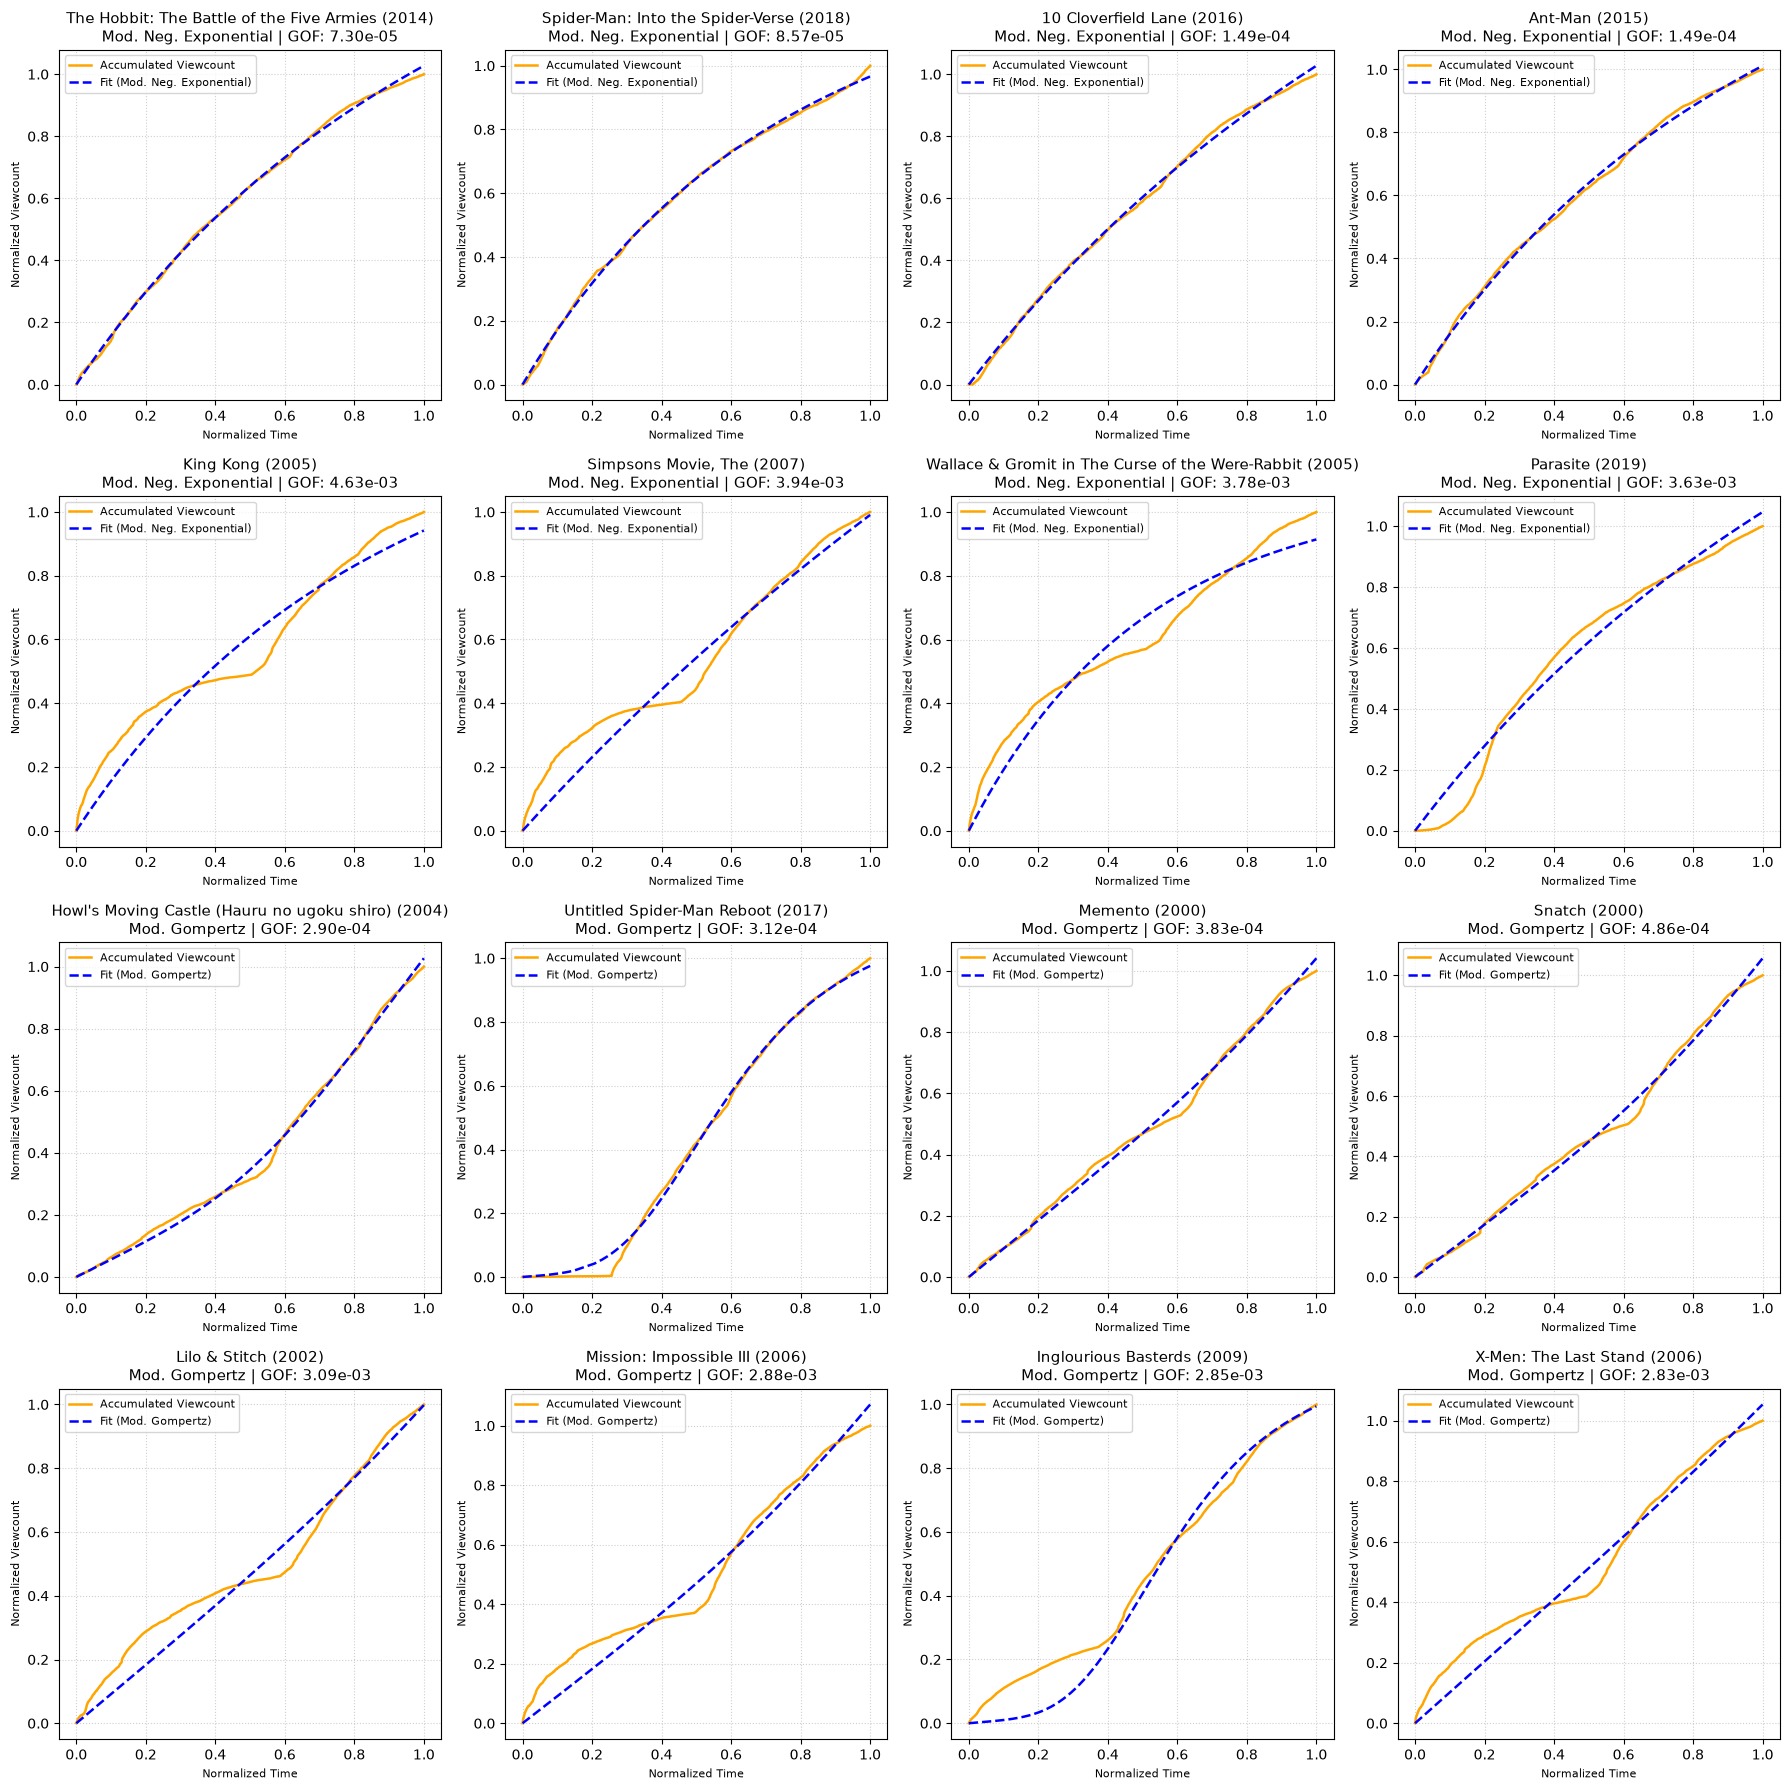

In [17]:
# Looking at the curves view counts of Mod Neg Exponential and Mod Gompertz

neg_exponential_best = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

neg_exponential_worst = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

mod_gom_best = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

mod_gom_worst = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

plot_df = pd.concat([
    neg_exponential_best, 
    neg_exponential_worst, 
    mod_gom_best, 
    mod_gom_worst
], ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()
for idx, (_, row) in enumerate(plot_df.iterrows()):
    movie_id = row["movieId"]
    model_name = row["best_model"]
    title = row["title"]
    lam = row["opt_lam"]
    k = row["opt_k"]

    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]
    S0 = y_vals[0] if y_vals[0] > 0 else 1e-5

    ax = axes[idx]
    ax.plot(t_vals, y_vals, label="Accumulated Viewcount", color="orange", linewidth=1.8)

    model_func = models[model_name]
    wrapped_func = two_par_wrapper(model_func, S0)
    y_pred = wrapped_func(t_vals, lam, k)

    ax.plot(t_vals, y_pred, label=f"Fit ({model_name})", color="blue",linestyle="dashed" ,linewidth=1.8)
    
   

    ax.set_title(f"{title}\n{model_name} | GOF: {row['GOF']:.2e}", fontsize=11)
    ax.set_xlabel("Normalized Time", fontsize=8)
    ax.set_ylabel("Normalized Viewcount", fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

After looking at the 4 best and worst results of modified negative xponential and modified gompertzt according to the GOF, we can conclude that for some movies our model captures the popularity dynamic extremly well and sufficiently good. however looking at our worst cases, reveals that for some movies we see a ratehr distinct number of peeks. most often two. This suggest that movie popularity unlike the studied youtube videos is much more complex. Over the lifetime of a movie it experiences multiple spikes in popularity, coinciding with an increase in user reviews in our dataset. These multiple peeks can not accuratly be captured by any of our models. 

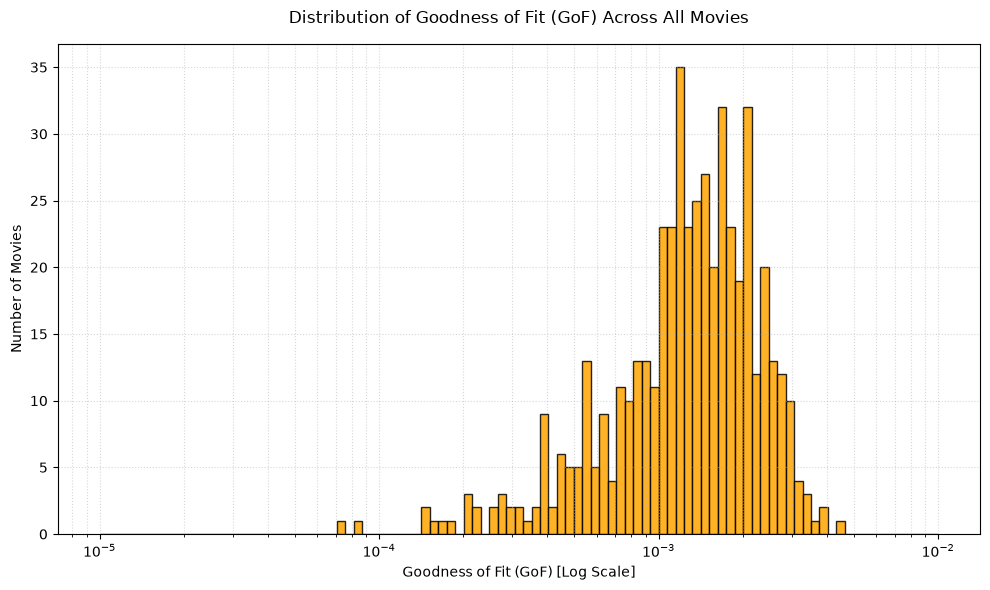

In [ ]:
gof_values = df_results["GOF"].values

min_log = np.floor(np.log10(gof_values.min()))
max_log = np.ceil(np.log10(gof_values.max()))
log_bins = np.logspace(min_log, max_log, 100)

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

ax.hist(
    gof_values,
    bins=log_bins,
    edgecolor="black",
    linewidth=1.0,
    alpha=0.85,
    color="orange"
)

ax.set_xscale("log")
ax.set_title("Distribution of Goodness of Fit (GoF) Across All Movies", fontsize=12, pad=15)
ax.set_xlabel("Goodness of Fit (GoF) [Log Scale]", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, which="both", linestyle=":", alpha=0.5)

plt.tight_layout()

looking at the distribution of the GOF across all our movies shows that movies in fact seem not to bes as accuratly captured by our bio inspired approach.
Compared to the GOF resutls from the paper, instead of most movies being comfortably below 10^-3 most of our movies have score worse than 10^-3 which is a stark difference to the papper resutls. However, this does not prevent us to fully analze our genrated data further.

# Predictive Quality
One of the most interesting parts of the original work was the investigation of predictive quality. We follow a similar investigation. We take the first 50% of a movies lifetime data, and then find the best model for it. we then compare our prediction with the actual data and see for how many movie our prediction stay belwo the threshold of MER < 0.05, which was choosen in the paper

In [20]:
prediction_results = []

for movie_id, data in movie_time_series.items():
    t_vals = data["t"]
    y_vals = data["y"]
    n_total = len(y_vals)
    
    
    if n_total < 10:                    # Makinf sure we have atleast a few reviews, should be no problem for top 500
        continue
    
    split_idx = n_total // 2
    
    t_train, y_train = t_vals[:split_idx], y_vals[:split_idx]
    t_test, y_test = t_vals[split_idx:], y_vals[split_idx:]
    
    if len(t_train) < 3 or len(t_test) < 3:
        continue

    best = get_best_fit(t_train, y_train, models, one_par_wrapper, two_par_wrapper)
    
    if best["gof"] is None or best["name"].startswith("Unclassified"):
        continue

    best_model_name = best["name"]
    best_lam = best["lam"]
    best_k = best["k"]

    S0_global = y_vals[0] if y_vals[0] > 0 else 1e-5
    
    if best_model_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
        wrapped_func_test = two_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam, best_k)
    else:
        wrapped_func_test = one_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam)

    test_mer = np.mean(np.abs(y_test - y_pred_test) / (y_test + 1.0))
    test_msc = np.sum((y_test - y_pred_test) ** 2)

    prediction_results.append({
        "movieId": movie_id,
        "title": data["title"],
        "selected_model": best_model_name,
        "test_MER": test_mer,
        "test_MSC": test_msc,
        "is_accurate": test_mer <= 0.05
    })

predictions_df = pd.DataFrame(prediction_results)

if not predictions_df.empty:
    success_rate = predictions_df['is_accurate'].mean() * 100
    print(f"\nPercentage of movies predicted with <= 5% MER on the second half: {success_rate:.2f}%")

/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")
/tmp/ipykernel_24727/1749490021.py:26: RuntimeWarning: overflow encountered in exp
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t
/tmp/ipykernel_24727/1749490021.py:26: RuntimeWarning: overflow encountered in multiply
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t



Percentage of movies predicted with <= 5% MER on the second half: 17.60%


We see we have only correctly predicted the future populairty for 17,60 % of movies. This is further evidencen that our models are not accuratly capturing the popularity over time

# Analyse movies in popularity classes
Another interesting point is grouping the movies into popularity classes.

Movies by Popularity Class:
popularity_bin
Very Unpopular (<100)      0
Unpopular (100-999)        0
Successful (1k-9.9k)     163
Popular (10k-99.9k)      337
Very Popular (100k+)       0
Name: count, dtype: int64


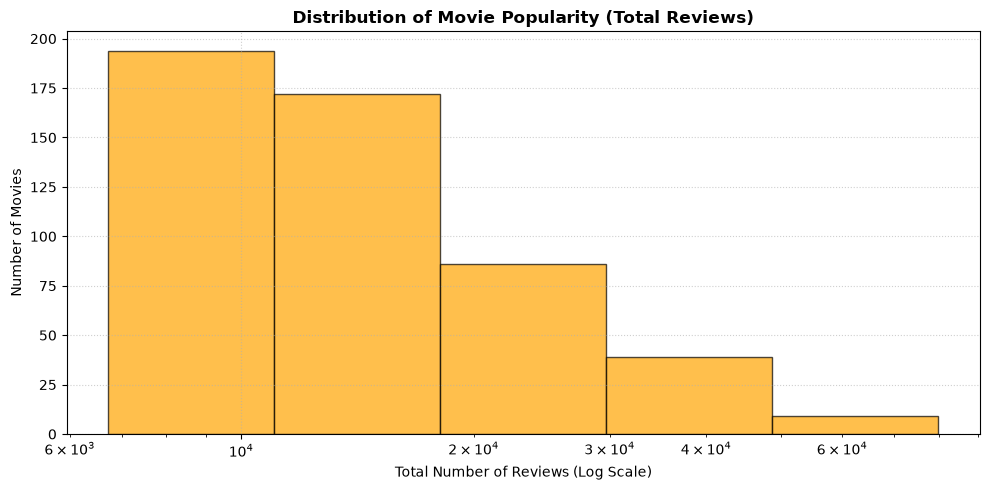

In [21]:
bin_edges = [0, 100, 1000, 10000, 100000, float("inf")]
bin_labels = [
    "Very Unpopular (<100)",
    "Unpopular (100-999)",
    "Successful (1k-9.9k)",
    "Popular (10k-99.9k)",
    "Very Popular (100k+)",
]

df_results["popularity_bin"] = pd.cut(
    df_results["total_reviews"], bins=bin_edges, labels=bin_labels, right=False
)

print("Movies by Popularity Class:")
print(df_results["popularity_bin"].value_counts(sort=False))

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

counts, edges, patches = ax.hist(
    df_results["total_reviews"].dropna(),
    bins=np.logspace(
        np.log10(max(1, df_results["total_reviews"].min())),
        np.log10(df_results["total_reviews"].max()),
        6,
    ),
    color="orange",
    edgecolor="black",
    alpha=0.7,
)

ax.set_xscale("log")
ax.set_title("Distribution of Movie Popularity (Total Reviews)", fontsize=12, fontweight="bold")
ax.set_xlabel("Total Number of Reviews (Log Scale)", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

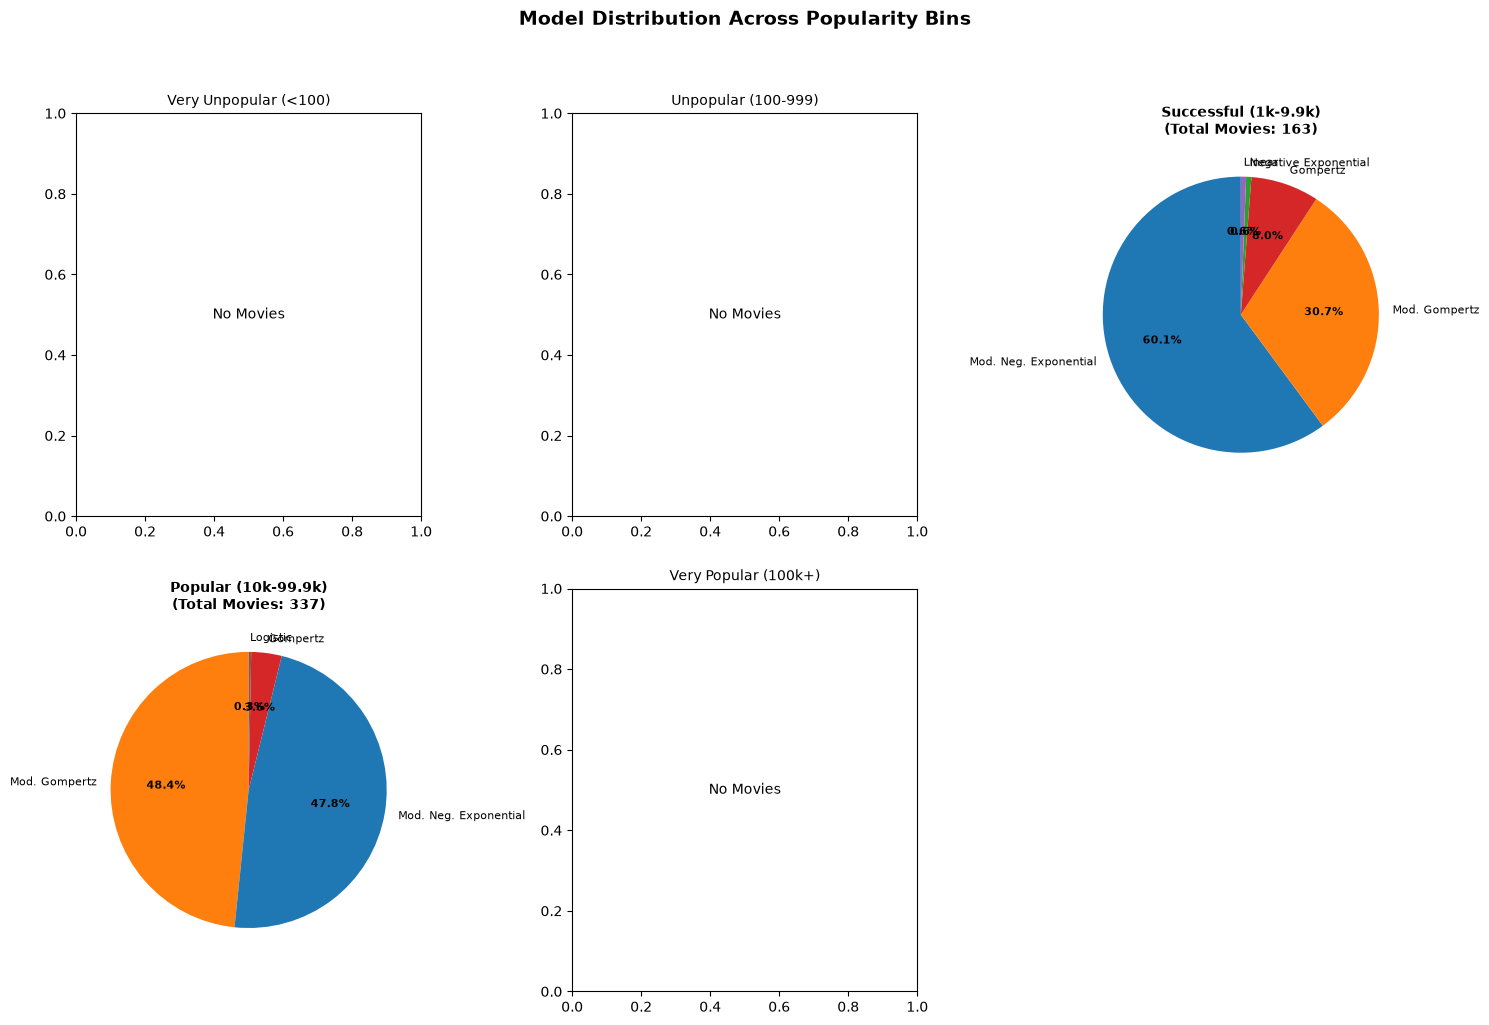

In [22]:
plot_df = df_results.dropna(subset=["popularity_bin", "best_model"])

bins_with_data = plot_df["popularity_bin"].dtype.categories

num_bins = len(bins_with_data)
if num_bins > 0:
    unique_models = plot_df["best_model"].unique()
    color_palette = plt.get_cmap("tab10").colors
    model_color_map = {
        model: color_palette[i % len(color_palette)] 
        for i, model in enumerate(unique_models)
    }

    cols = 3
    rows = (num_bins + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    if num_bins == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    for idx, bin_name in enumerate(bins_with_data):
        ax = axes[idx]
        
        sub_df = plot_df[plot_df["popularity_bin"] == bin_name]
        model_counts = sub_df["best_model"].value_counts()
        
        if not model_counts.empty:
            bin_colors = [model_color_map[model] for model in model_counts.index]
            
            wedges, texts, autotexts = ax.pie(
                model_counts.values, 
                labels=model_counts.index, 
                colors=bin_colors,
                autopct='%1.1f%%', 
                startangle=90,
                textprops=dict(fontsize=8)
            )
            plt.setp(autotexts, size=8, weight="bold")
            ax.set_title(f"{bin_name}\n(Total Movies: {len(sub_df)})", fontsize=10, fontweight="bold")
        else:
            ax.text(0.5, 0.5, "No Movies", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.set_title(f"{bin_name}", fontsize=10)

    for j in range(num_bins, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Model Distribution Across Popularity Bins", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
else:
    print("No data available in popularity bins to plot.")

We can see that for popular movies the sahre of viral movies increase from roughly 38% (gompertz and modified gompertz) to 50%. So amongst the most popular movies we see the share of ciral movies increase significantly. This suggest that to get a truly popular movie you can not relly simply on huge marketing campagnes and you need word far more a word of mouth viral spread to get a movie in this category.

# Find if the top 10% by rating movies are in which growth class
another intersting stat would be too look at the top movies by average rating. the top 10 movies

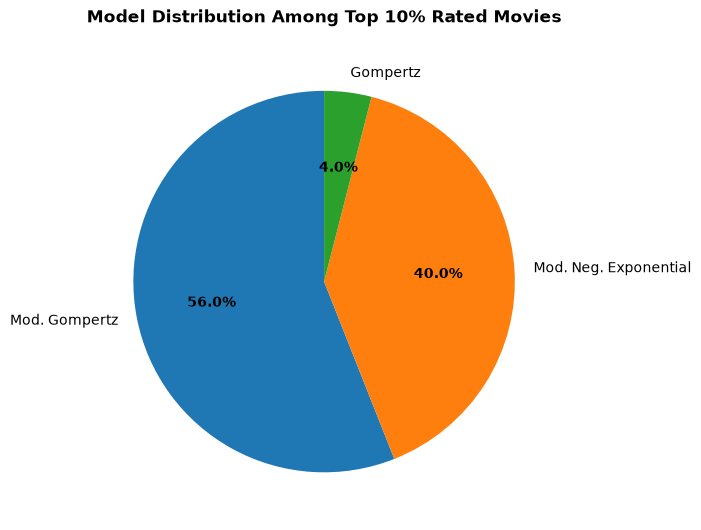

In [23]:
top_rated = df_results.sort_values(by="avg_rating", ascending=False).head(50)

model_counts = top_rated["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    labels=model_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold")
ax.set_title("Model Distribution Among Top 10% Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()



We see the most popular models are 60% viral and only 40% are non viral growth patern movies

# Experiments using 10_000 movies after 2000

In [25]:
import pandas as pd
import numpy as np

TOP_N = 10_000

In [26]:
movies_dtype = {
    "movieId": "int32",
    "title": "string",
    "genres": "string"
}
ratings_dtype = {
    "userId": "int32",
    "movieId": "int32",
    "rating": "float32",
    "timestamp": "int64"
}
movies_df = pd.read_csv("./../data/ml-latest/movies.csv", dtype=movies_dtype)
ratings_df = pd.read_csv("./../data/ml-latest/ratings.csv", dtype=ratings_dtype)


# Fill in release year based on regex from title as col
movies_df["year"] = movies_df["title"].str.extract(r"\((\d{4})\)").astype("Int64")
recent_movies = movies_df[movies_df["year"] >= 2000].copy()


recent_movie_ids = recent_movies["movieId"]
review_counts = ratings_df["movieId"].value_counts()
review_counts.head()
recent_movie_review_counts = review_counts[review_counts.index.isin(recent_movie_ids)]

top_movie_ids = recent_movie_review_counts.nlargest(TOP_N).index.values

# Filter the movies
movies_df = recent_movies[recent_movies["movieId"].isin(top_movie_ids)]
ratings_df = ratings_df[ratings_df["movieId"].isin(top_movie_ids)]


print(f"Movies: {movies_df.shape}")
print(f"Ratings: {ratings_df.shape}")

Movies: (10000, 4)
Ratings: (13961279, 4)


In [27]:
movie_time_series = {}

for movie_id in movies_df["movieId"]:
    movie_ratings = ratings_df[ratings_df["movieId"] == movie_id].sort_values("timestamp")
    timestamps = movie_ratings["timestamp"].values


    elapsed_time = timestamps - timestamps[0]
    total_time = elapsed_time[-1]

    cumulative_counts = np.arange(1, len(movie_ratings) + 1, dtype=float)
    max_count = cumulative_counts[-1]

    t_norm = elapsed_time / total_time if total_time > 0 else elapsed_time
    y_norm = cumulative_counts / max_count

    movie_time_series[movie_id] = {
        "title": movies_df.loc[movies_df["movieId"] == movie_id, "title"].values[0],
        "t": t_norm,
        "y": y_norm,
        "total_reviews": max_count,
        "avg_rating": movie_ratings["rating"].mean()
    }

In [28]:
results = []

for movie_id, data in movie_time_series.items():
    best = get_best_fit(data["t"], data["y"], models, one_par_wrapper, two_par_wrapper)

    results.append({
        "movieId": movie_id,
        "title": data["title"],
        "total_reviews": data["total_reviews"],
        "avg_rating": data["avg_rating"],
        "best_model": best["name"],
        "MER": best["mer"],
        "GOF": best["gof"],
        "MSC": best["msc"],
        "opt_lam": best["lam"],
        "opt_k": best["k"]
    })

df_results = pd.DataFrame(results)
print(df_results["best_model"].value_counts())

/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")


best_model
Mod. Neg. Exponential    7311
Mod. Gompertz            1147
Gompertz                  676
Negative Exponential      558
Logistic                  165
Linear                    143
Name: count, dtype: int64


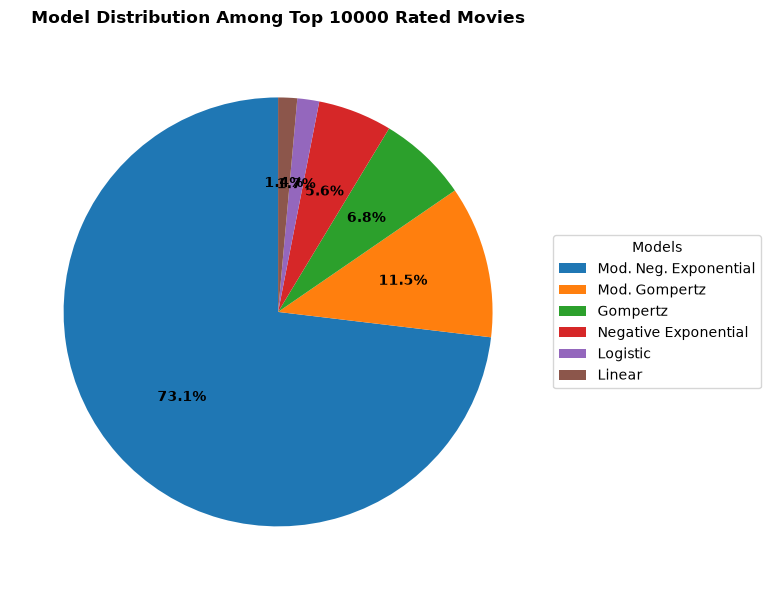

In [29]:
model_counts = df_results["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold", color="black")

ax.legend(
    wedges, 
    model_counts.index, 
    title="Models", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1)
)

ax.set_title(f"Model Distribution Among Top {TOP_N} Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()

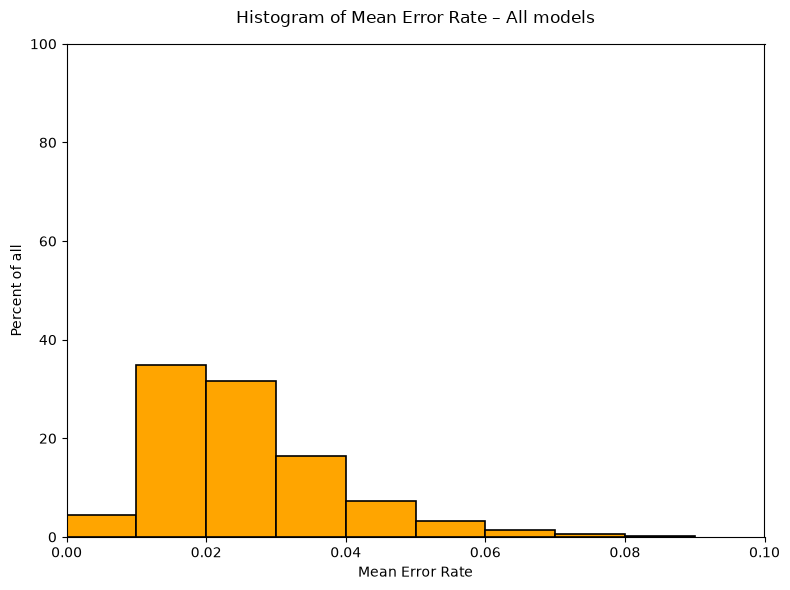

In [30]:
mer_data = df_results["MER"].dropna().values

bins = np.arange(0.0, 0.1, 0.01)

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

weights = np.ones(len(mer_data)) / len(mer_data) * 100

ax.hist(
    mer_data,
    bins=bins,
    weights=weights,
    color="orange",
    edgecolor="black",
    linewidth=1.2,
)

ax.set_title("Histogram of Mean Error Rate – All models", fontsize=12, pad=15)
ax.set_xlabel("Mean Error Rate", fontsize=10)
ax.set_ylabel("Percent of all", fontsize=10)

ax.set_xlim(0.00, 0.1)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

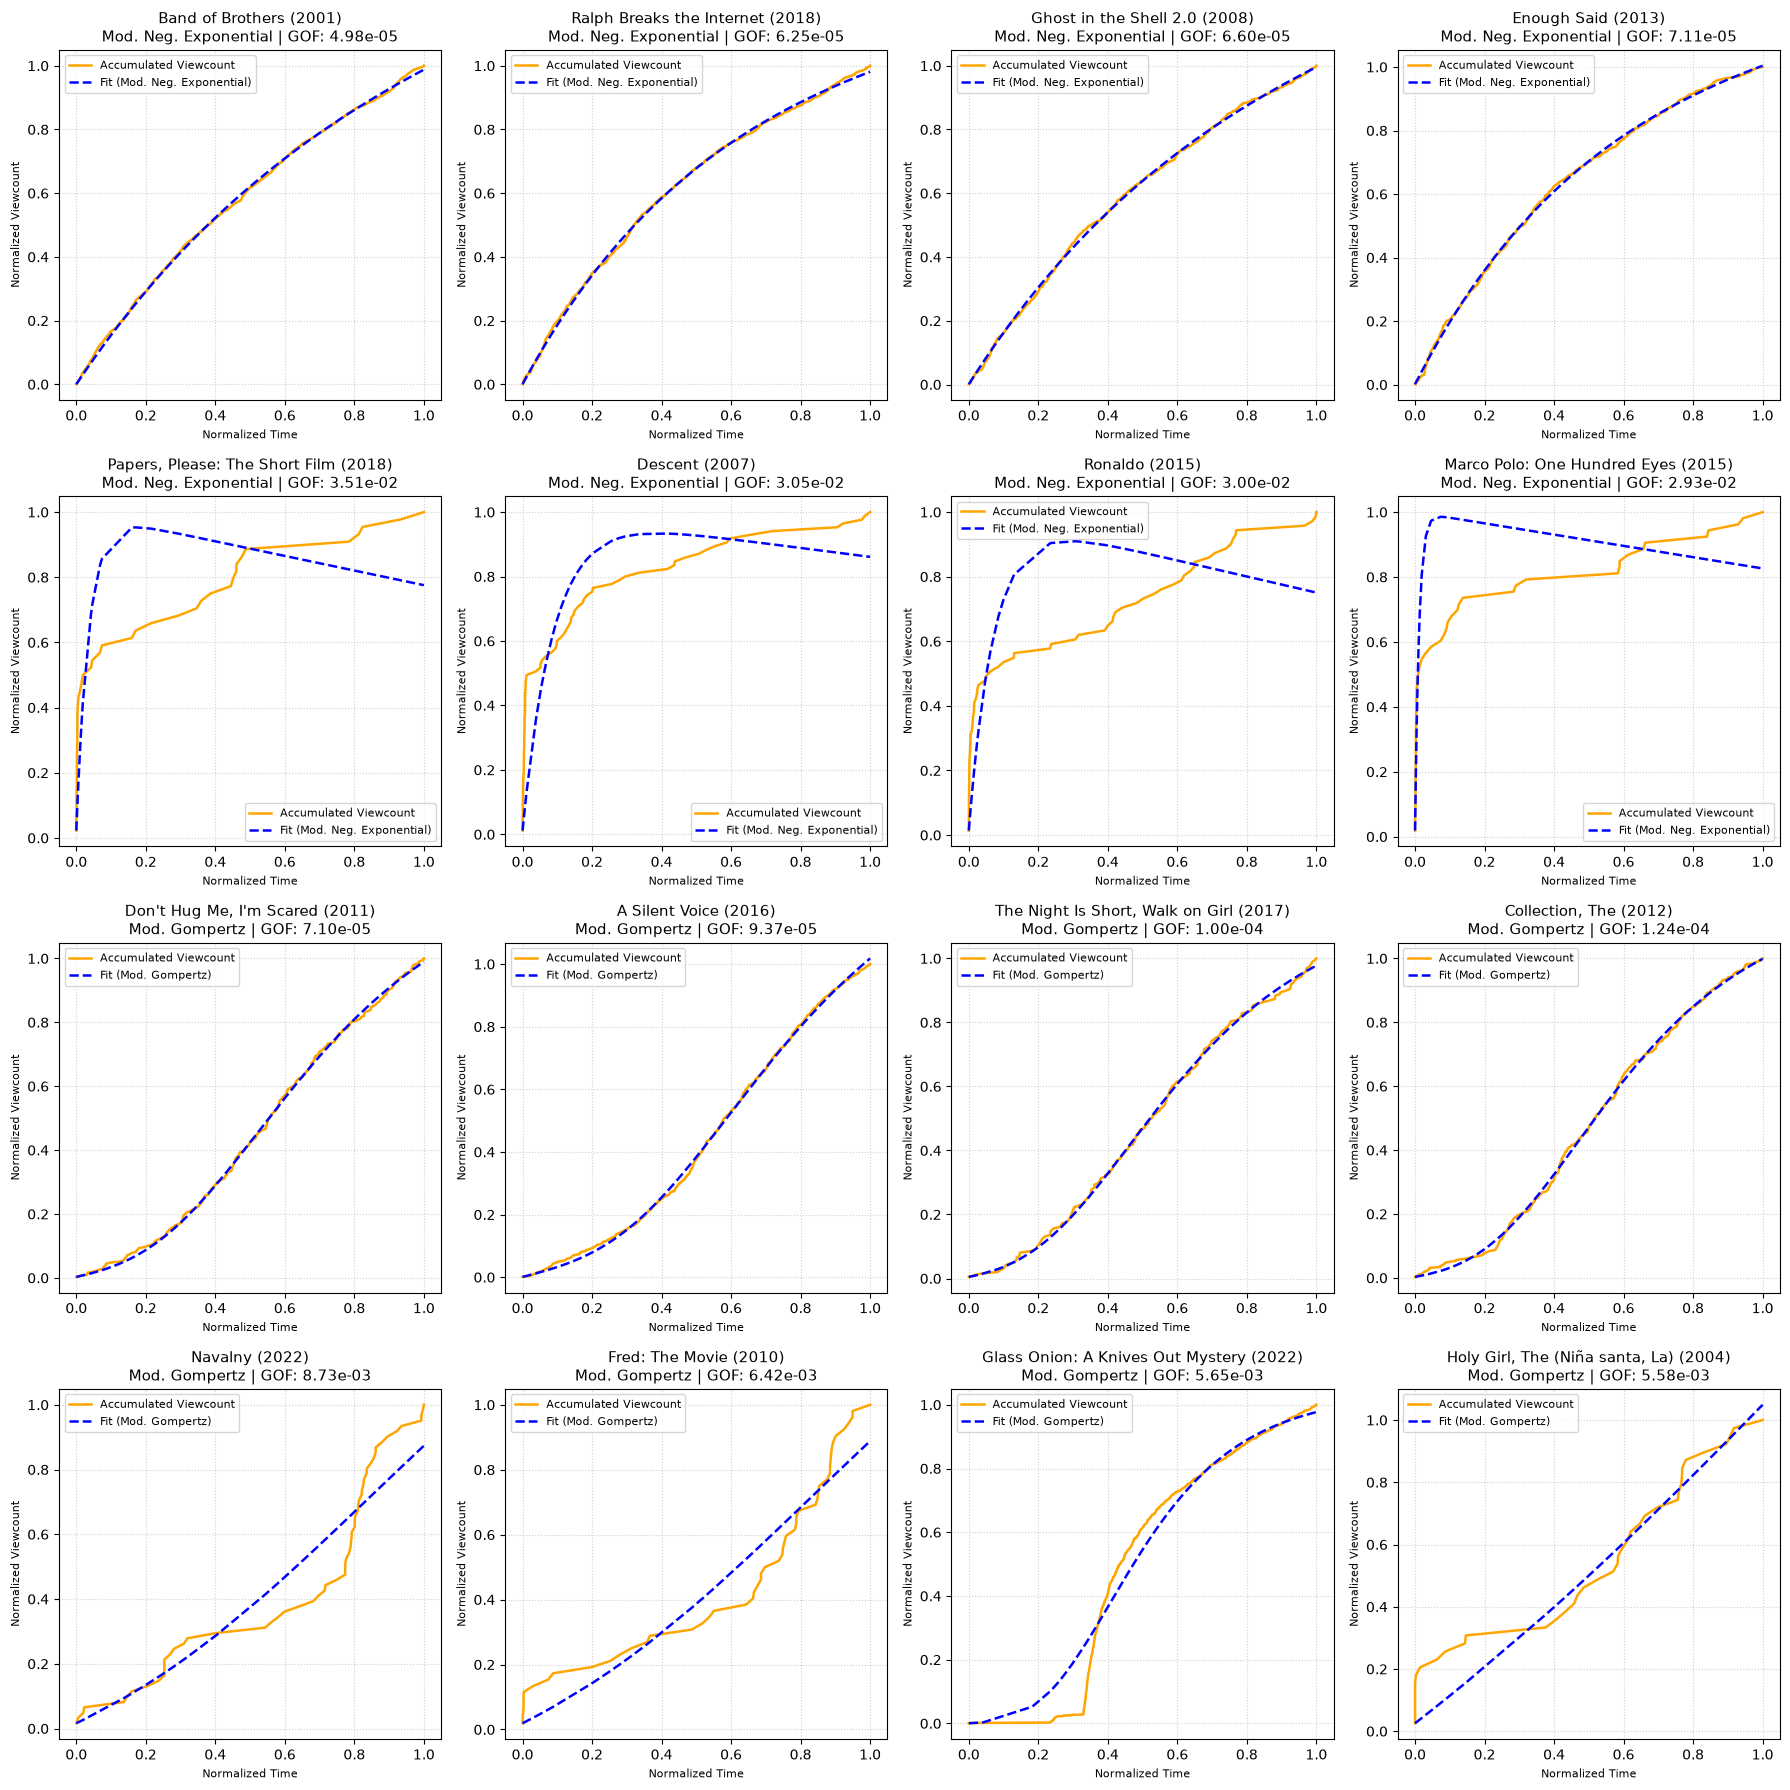

In [31]:
# Looking at the curves view counts of Mod Neg Exponential and Mod Gompertz

neg_exponential_best = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

neg_exponential_worst = (
    df_results[df_results["best_model"] == "Mod. Neg. Exponential"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

mod_gom_best = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = True)       # Lowest GOF best fit
    .head(4)
)

mod_gom_worst = (
    df_results[df_results["best_model"] == "Mod. Gompertz"]
    .sort_values(by="GOF", ascending = False)       # Lowest GOF best fit
    .head(4)
)

df = pd.concat([
    neg_exponential_best, 
    neg_exponential_worst, 
    mod_gom_best, 
    mod_gom_worst
], ignore_index=True)

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()
for idx, (_, row) in enumerate(df.iterrows()):
    movie_id = row["movieId"]
    model_name = row["best_model"]
    title = row["title"]
    lam = row["opt_lam"]
    k = row["opt_k"]

    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]
    S0 = y_vals[0] if y_vals[0] > 0 else 1e-5

    ax = axes[idx]
    ax.plot(t_vals, y_vals, label="Accumulated Viewcount", color="orange", linewidth=1.8)

    model_func = models[model_name]
    wrapped_func = two_par_wrapper(model_func, S0)
    y_pred = wrapped_func(t_vals, lam, k)

    ax.plot(t_vals, y_pred, label=f"Fit ({model_name})", color="blue",linestyle="dashed" ,linewidth=1.8)
    
   

    ax.set_title(f"{title}\n{model_name} | GOF: {row['GOF']:.2e}", fontsize=11)
    ax.set_xlabel("Normalized Time", fontsize=8)
    ax.set_ylabel("Normalized Viewcount", fontsize=8)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

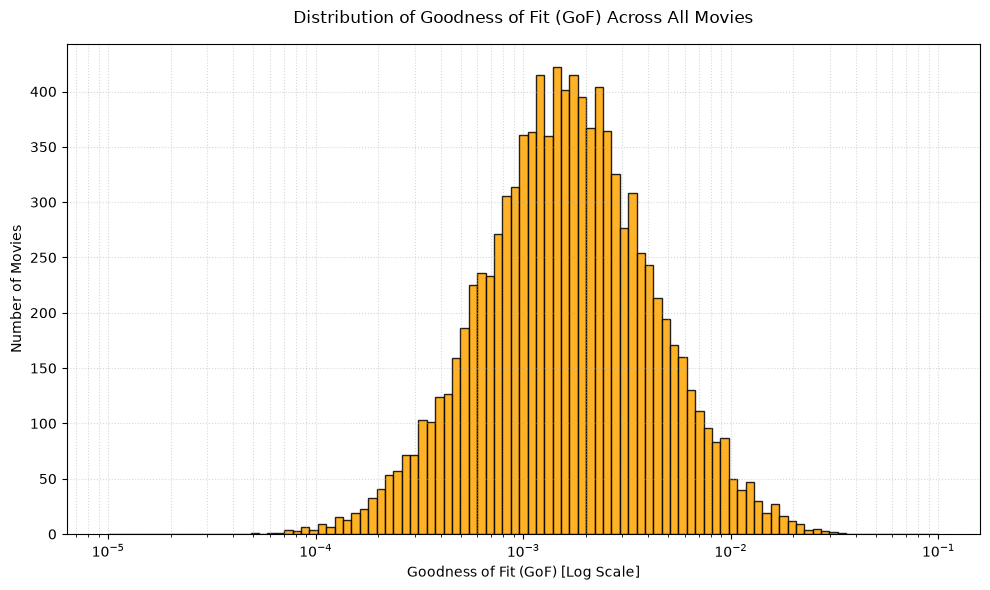

In [32]:
gof_values = df_results["GOF"].values

min_log = np.floor(np.log10(gof_values.min()))
max_log = np.ceil(np.log10(gof_values.max()))
log_bins = np.logspace(min_log, max_log, 100)

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

ax.hist(
    gof_values,
    bins=log_bins,
    edgecolor="black",
    linewidth=1.0,
    alpha=0.85,
    color="orange"
)

ax.set_xscale("log")
ax.set_title("Distribution of Goodness of Fit (GoF) Across All Movies", fontsize=12, pad=15)
ax.set_xlabel("Goodness of Fit (GoF) [Log Scale]", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, which="both", linestyle=":", alpha=0.5)

plt.tight_layout()


In [33]:
prediction_results = []

for movie_id, data in movie_time_series.items():
    t_vals = data["t"]
    y_vals = data["y"]
    n_total = len(y_vals)
    
    
    if n_total < 10:                    # Makinf sure we have atleast a few reviews, should be no problem for top 500
        continue
    
    split_idx = n_total // 2
    
    t_train, y_train = t_vals[:split_idx], y_vals[:split_idx]
    t_test, y_test = t_vals[split_idx:], y_vals[split_idx:]
    
    if len(t_train) < 3 or len(t_test) < 3:
        continue

    best = get_best_fit(t_train, y_train, models, one_par_wrapper, two_par_wrapper)
    
    if best["gof"] is None or best["name"].startswith("Unclassified"):
        continue

    best_model_name = best["name"]
    best_lam = best["lam"]
    best_k = best["k"]

    S0_global = y_vals[0] if y_vals[0] > 0 else 1e-5
    
    if best_model_name in ["Mod. Neg. Exponential", "Mod. Gompertz"]:
        wrapped_func_test = two_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam, best_k)
    else:
        wrapped_func_test = one_par_wrapper(models[best_model_name], S0_global)
        y_pred_test = wrapped_func_test(t_test, best_lam)

    test_mer = np.mean(np.abs(y_test - y_pred_test) / (y_test + 1.0))
    test_msc = np.sum((y_test - y_pred_test) ** 2)

    prediction_results.append({
        "movieId": movie_id,
        "title": data["title"],
        "selected_model": best_model_name,
        "test_MER": test_mer,
        "test_MSC": test_msc,
        "is_accurate": test_mer <= 0.05
    })

predictions_df = pd.DataFrame(prediction_results)

if not predictions_df.empty:
    success_rate = predictions_df['is_accurate'].mean() * 100
    print(f"\nPercentage of movies predicted with <= 5% MER on the second half: {success_rate:.2f}%")

/tmp/ipykernel_24727/1749490021.py:26: RuntimeWarning: overflow encountered in exp
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t
/tmp/ipykernel_24727/1749490021.py:61: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(wrapped_func, t_vals, y_vals, p0=p0, method="lm")
/tmp/ipykernel_24727/1749490021.py:26: RuntimeWarning: overflow encountered in multiply
  return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t



Percentage of movies predicted with <= 5% MER on the second half: 17.38%


Movies by Popularity Class:
popularity_bin
Very Unpopular (<100)    3582
Unpopular (100-999)      4284
Successful (1k-9.9k)     1797
Popular (10k-99.9k)       337
Very Popular (100k+)        0
Name: count, dtype: int64


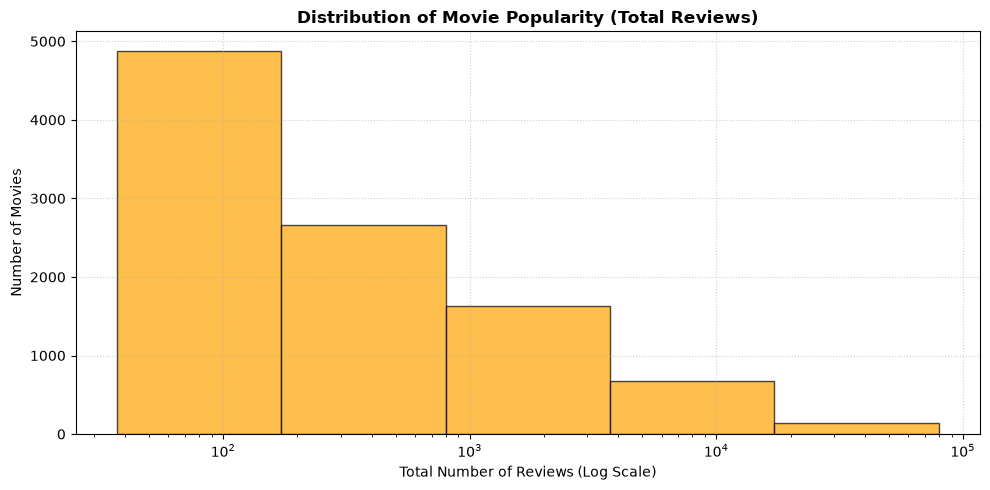

In [34]:
bin_edges = [0, 100, 1000, 10000, 100000, float("inf")]
bin_labels = [
    "Very Unpopular (<100)",
    "Unpopular (100-999)",
    "Successful (1k-9.9k)",
    "Popular (10k-99.9k)",
    "Very Popular (100k+)",
]

df_results["popularity_bin"] = pd.cut(
    df_results["total_reviews"], bins=bin_edges, labels=bin_labels, right=False
)

print("Movies by Popularity Class:")
print(df_results["popularity_bin"].value_counts(sort=False))

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

counts, edges, patches = ax.hist(
    df_results["total_reviews"].dropna(),
    bins=np.logspace(
        np.log10(max(1, df_results["total_reviews"].min())),
        np.log10(df_results["total_reviews"].max()),
        6,
    ),
    color="orange",
    edgecolor="black",
    alpha=0.7,
)

ax.set_xscale("log")
ax.set_title("Distribution of Movie Popularity (Total Reviews)", fontsize=12, fontweight="bold")
ax.set_xlabel("Total Number of Reviews (Log Scale)", fontsize=10)
ax.set_ylabel("Number of Movies", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

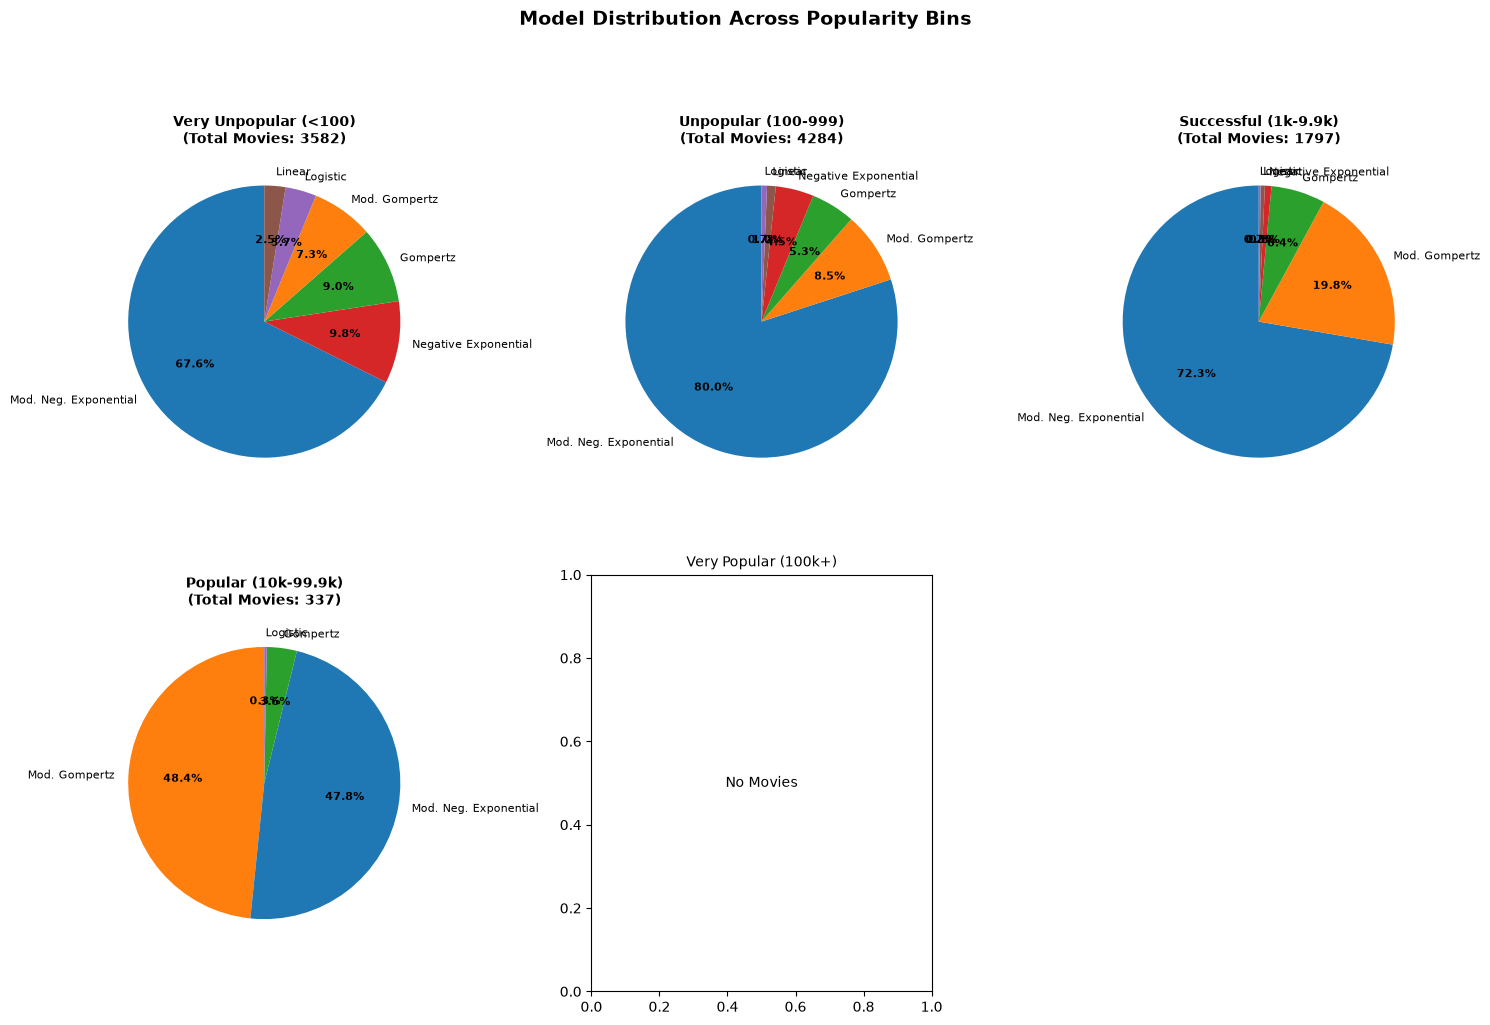

In [35]:
plot_df = df_results.dropna(subset=["popularity_bin", "best_model"])

bins_with_data = plot_df["popularity_bin"].dtype.categories

num_bins = len(bins_with_data)
if num_bins > 0:
    unique_models = plot_df["best_model"].unique()
    color_palette = plt.get_cmap("tab10").colors
    model_color_map = {
        model: color_palette[i % len(color_palette)] 
        for i, model in enumerate(unique_models)
    }

    cols = 3
    rows = (num_bins + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    if num_bins == 1:
        axes = np.array([axes])
    else:
        axes = axes.flatten()

    for idx, bin_name in enumerate(bins_with_data):
        ax = axes[idx]
        
        sub_df = plot_df[plot_df["popularity_bin"] == bin_name]
        model_counts = sub_df["best_model"].value_counts()
        
        if not model_counts.empty:
            bin_colors = [model_color_map[model] for model in model_counts.index]
            
            wedges, texts, autotexts = ax.pie(
                model_counts.values, 
                labels=model_counts.index, 
                colors=bin_colors,
                autopct='%1.1f%%', 
                startangle=90,
                textprops=dict(fontsize=8)
            )
            plt.setp(autotexts, size=8, weight="bold")
            ax.set_title(f"{bin_name}\n(Total Movies: {len(sub_df)})", fontsize=10, fontweight="bold")
        else:
            ax.text(0.5, 0.5, "No Movies", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
            ax.set_title(f"{bin_name}", fontsize=10)

    for j in range(num_bins, len(axes)):
        axes[j].axis('off')

    plt.suptitle("Model Distribution Across Popularity Bins", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
else:
    print("No data available in popularity bins to plot.")

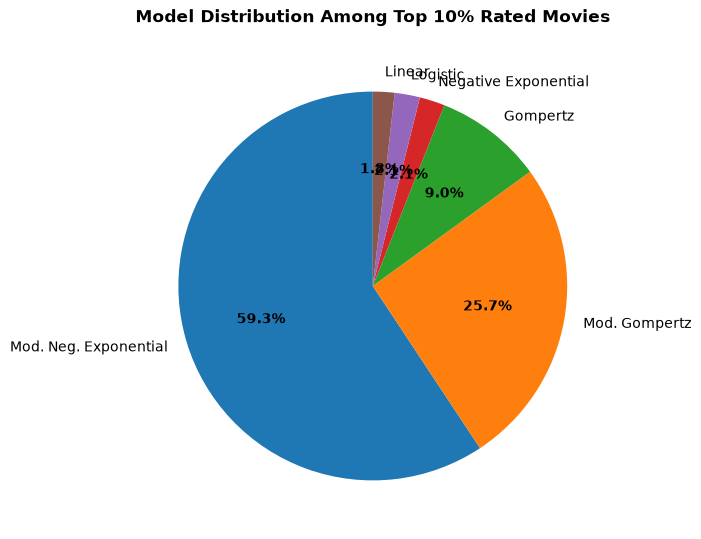

In [36]:
top_rated = df_results.sort_values(by="avg_rating", ascending=False).head(int(TOP_N*0.1))

model_counts = top_rated["best_model"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)

wedges, texts, autotexts = ax.pie(
    model_counts.values,
    labels=model_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops=dict(fontsize=10)
)

plt.setp(autotexts, size=10, weight="bold")
ax.set_title("Model Distribution Among Top 10% Rated Movies", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()



# Citattions

1. > F. Maxwell Harper and Joseph A. Konstan. 2015. The MovieLens Datasets: History and Context. ACM Transactions on Interactive Intelligent Systems (TiiS) 5, 4: 19:1–19:19. <https://doi.org/10.1145/2827872>

2. Cedric Richier, Eitan Altman, Rachid El-Azouzi, Tania Jimenez, Georges Linarès, et al.. Bio-Inspired
Models for Characterizing YouTube Viewcount. IEEE/ACM International Conference on Advances
in Social Networks Analysis and Mining (ASONAM 2014), Aug 2014, Beijing, China. pp.297-305,
⟨10.1109/ASONAM.2014.6921600⟩. ⟨hal-01011069
